In [8]:
# ПР 12. Анализ временных рядов
# Датасет: Daily minimum temperatures (Мельбурн, 1981-1990)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf
from pmdarima.arima import auto_arima
from sklearn.metrics import mean_squared_error

import warnings
warnings.filterwarnings('ignore')

# ============================================================
# 1. ЗАГРУЗКА ДАННЫХ
# ============================================================

df = pd.read_csv('data/pr12/dataset.csv')

print("Первые 5 строк:")
print(df.head())

print("\nИнформация о данных:")
print(df.info())

# стандартизируем названия колонок (Date и Temp)
if 'Date' in df.columns:
    df['date'] = pd.to_datetime(df['Date'])
    df.drop('Date', axis=1, inplace=True)
elif 'date' in df.columns:
    df['date'] = pd.to_datetime(df['date'])

if 'Temp' in df.columns:
    df.rename(columns={'Temp': 'temperature'}, inplace=True)
elif 'temperature' in df.columns:
    pass
else:
    # если колонка называется иначе, берём первый числовой столбец
    num_cols = df.select_dtypes(include=[np.number]).columns
    df.rename(columns={num_cols[0]: 'temperature'}, inplace=True)

df.set_index('date', inplace=True)
df.sort_index(inplace=True)

print(f"\nРазмер данных: {len(df)}")
print(df.head())

Первые 5 строк:
         Date  Temp
0  1981-01-01  20.7
1  1981-01-02  17.9
2  1981-01-03  18.8
3  1981-01-04  14.6
4  1981-01-05  15.8

Информация о данных:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3650 entries, 0 to 3649
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    3650 non-null   object 
 1   Temp    3650 non-null   float64
dtypes: float64(1), object(1)
memory usage: 57.2+ KB
None

Размер данных: 3650
            temperature
date                   
1981-01-01         20.7
1981-01-02         17.9
1981-01-03         18.8
1981-01-04         14.6
1981-01-05         15.8


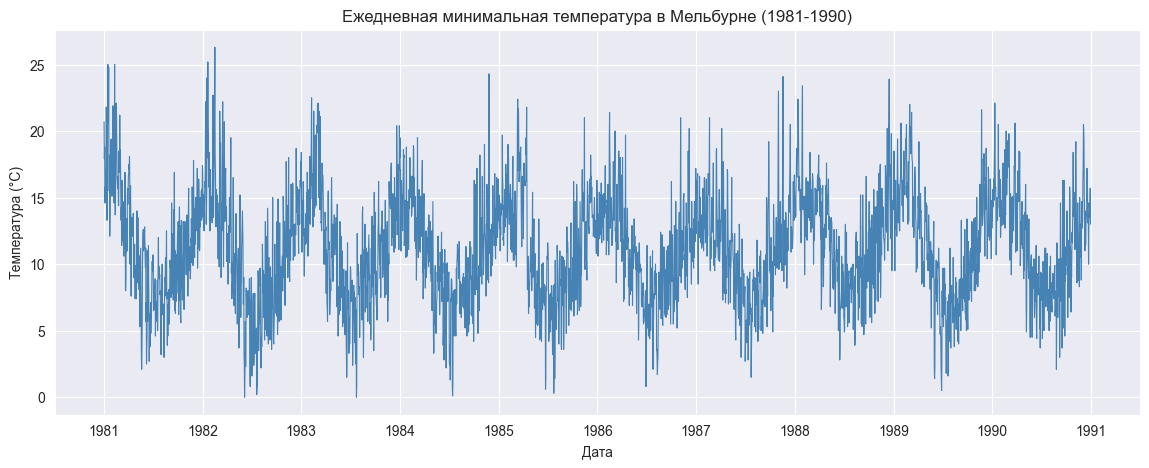

In [9]:
# ============================================================
# 2. ВИЗУАЛИЗАЦИЯ РЯДА
# ============================================================

plt.figure(figsize=(14, 5))
plt.plot(df.index, df['temperature'], color='steelblue', linewidth=0.8)
plt.title('Ежедневная минимальная температура в Мельбурне (1981-1990)')
plt.xlabel('Дата')
plt.ylabel('Температура (°C)')
plt.grid(True)
plt.show()

In [10]:
# ============================================================
# 3. ПРОВЕРКА НА СТАЦИОНАРНОСТЬ (тест Дики-Фуллера)
# ============================================================

def check_stationarity(series, title='ряда'):
    result = adfuller(series.dropna())
    print(f'Тест Дики-Фуллера для {title}:')
    print(f'  ADF статистика: {result[0]:.4f}')
    print(f'  p-value: {result[1]:.4f}')
    print(f'  Критические значения:')
    for key, val in result[4].items():
        print(f'    {key}: {val:.4f}')

    if result[1] <= 0.05:
        print(f'  Вывод: ряд СТАЦИОНАРЕН')
        return True
    else:
        print(f'  Вывод: ряд НЕСТАЦИОНАРЕН')
        return False

is_stationary = check_stationarity(df['temperature'], 'исходного ряда')

Тест Дики-Фуллера для исходного ряда:
  ADF статистика: -4.4448
  p-value: 0.0002
  Критические значения:
    1%: -3.4322
    5%: -2.8623
    10%: -2.5672
  Вывод: ряд СТАЦИОНАРЕН


In [11]:
# ============================================================
# 4. ПРИВЕДЕНИЕ К СТАЦИОНАРНОСТИ (если нужно)
# ============================================================

if not is_stationary:
    df['log'] = np.log(df['temperature'])
    df['diff'] = df['temperature'].diff()
    df['log_diff'] = df['log'].diff()

    # Проверяем преобразованный ряд
    is_stationary_transformed = check_stationarity(df['log_diff'].dropna(), 'логарифмической разности')

    # Выбираем лучший вариант для модели
    target_series = df['log_diff'].dropna()
else:
    target_series = df['temperature'].copy()

print(f"\nВыбрана целевая переменная для моделирования")


Выбрана целевая переменная для моделирования


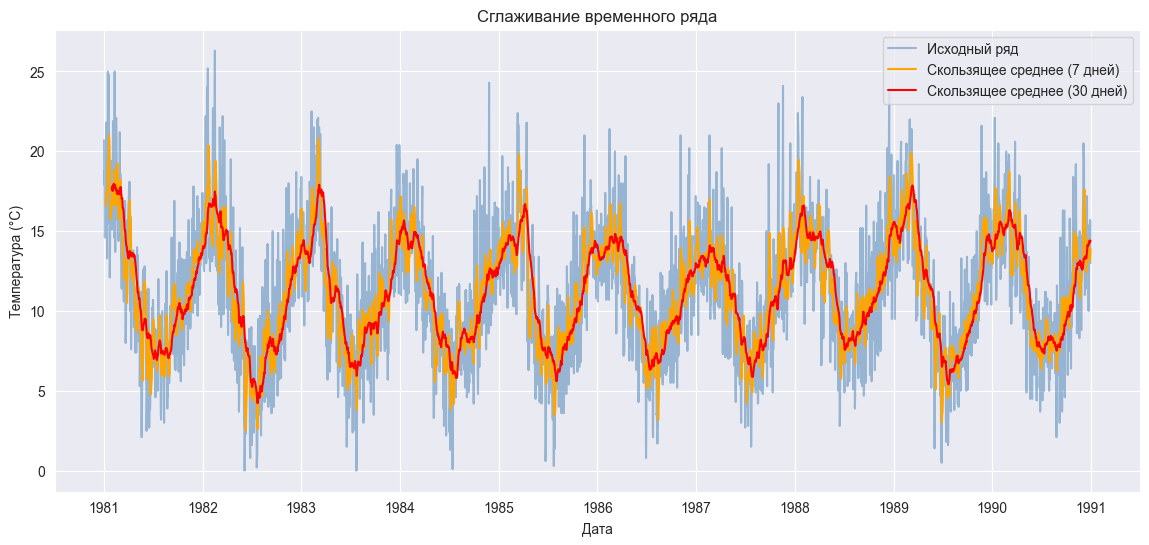

In [12]:
# ============================================================
# 5. СГЛАЖИВАНИЕ (скользящее среднее)
# ============================================================

df['MA_7'] = df['temperature'].rolling(window=7).mean()   # неделя
df['MA_30'] = df['temperature'].rolling(window=30).mean() # месяц

plt.figure(figsize=(14, 6))
plt.plot(df.index, df['temperature'], label='Исходный ряд', alpha=0.5, color='steelblue')
plt.plot(df.index, df['MA_7'], label='Скользящее среднее (7 дней)', color='orange')
plt.plot(df.index, df['MA_30'], label='Скользящее среднее (30 дней)', color='red')
plt.title('Сглаживание временного ряда')
plt.xlabel('Дата')
plt.ylabel('Температура (°C)')
plt.legend()
plt.grid(True)
plt.show()

<Figure size 1200x500 with 0 Axes>

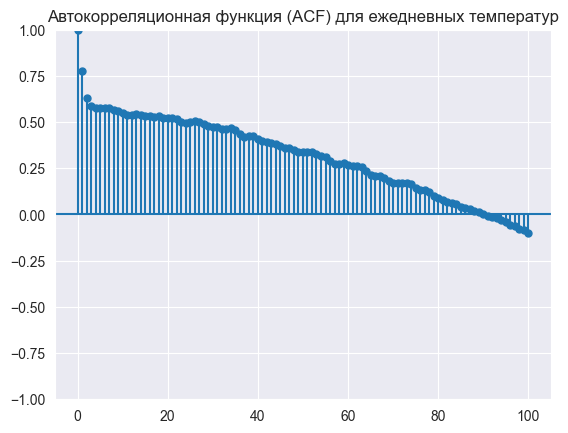

In [13]:
# ============================================================
# 6. АВТОКОРРЕЛЯЦИЯ (ACF)
# ============================================================

plt.figure(figsize=(12, 5))
plot_acf(df['temperature'].dropna(), lags=100, alpha=None)
plt.title('Автокорреляционная функция (ACF) для ежедневных температур')
plt.grid(True)
plt.show()

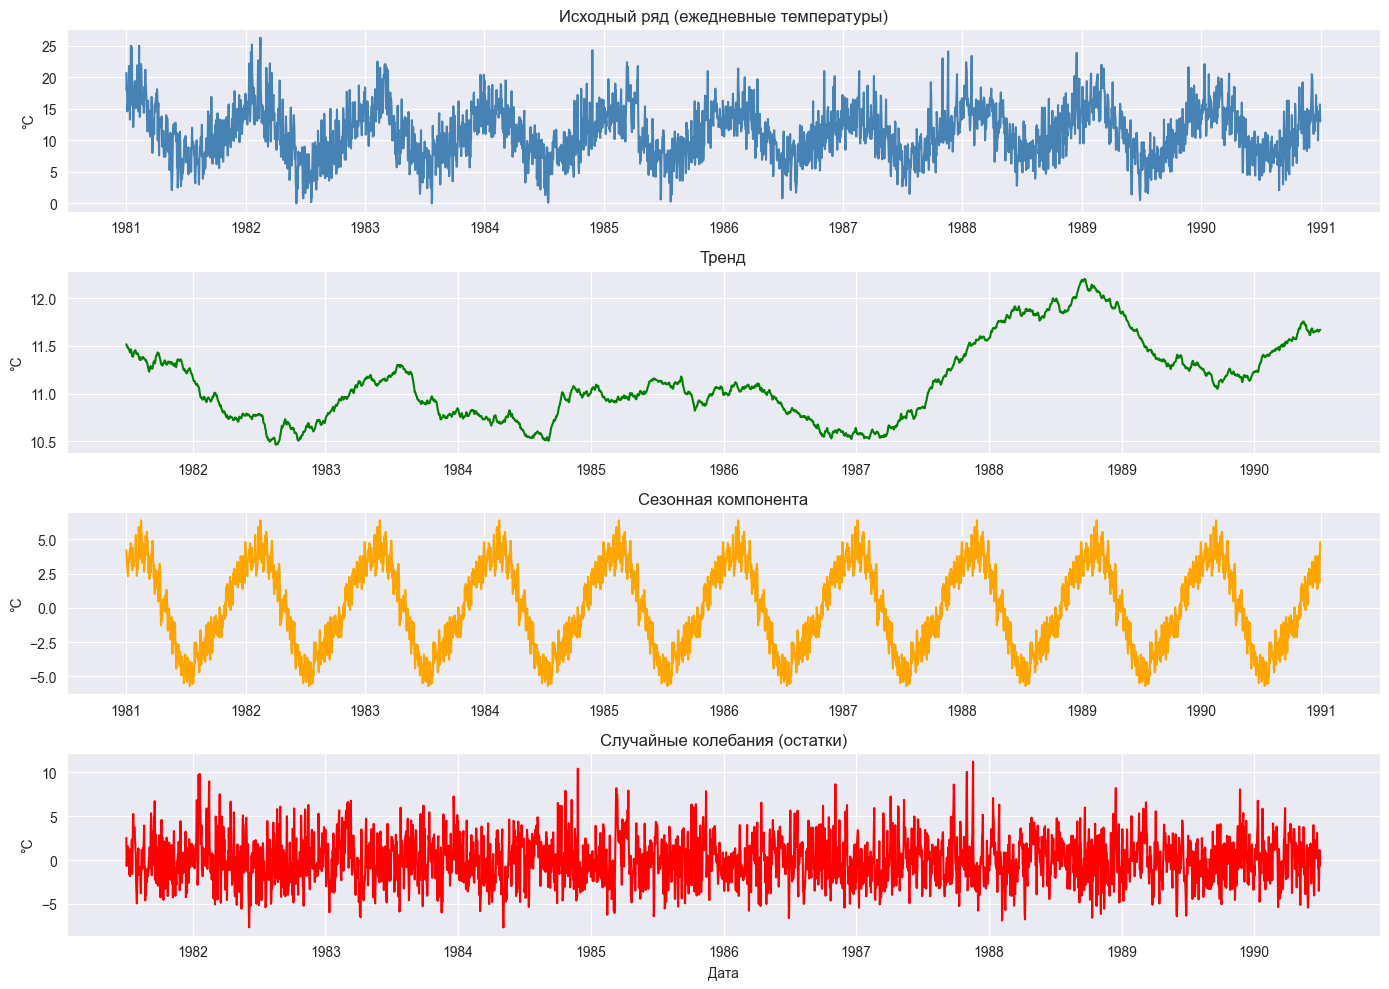

In [14]:
# ============================================================
# 7. РАЗЛОЖЕНИЕ НА ТРЕНД + СЕЗОННОСТЬ
# ============================================================

# для ежедневных данных сезонность = 365 дней
seasonal_period = 365

# заполняем пропуски интерполяцией
series_clean = df['temperature'].interpolate()

decompose = seasonal_decompose(series_clean, model='additive', period=seasonal_period)

fig, axes = plt.subplots(4, 1, figsize=(14, 10))

axes[0].plot(decompose.observed, color='steelblue')
axes[0].set_title('Исходный ряд (ежедневные температуры)')
axes[0].set_ylabel('°C')

axes[1].plot(decompose.trend, color='green')
axes[1].set_title('Тренд')
axes[1].set_ylabel('°C')

axes[2].plot(decompose.seasonal, color='orange')
axes[2].set_title('Сезонная компонента')
axes[2].set_ylabel('°C')

axes[3].plot(decompose.resid, color='red')
axes[3].set_title('Случайные колебания (остатки)')
axes[3].set_ylabel('°C')
axes[3].set_xlabel('Дата')

plt.tight_layout()
plt.show()

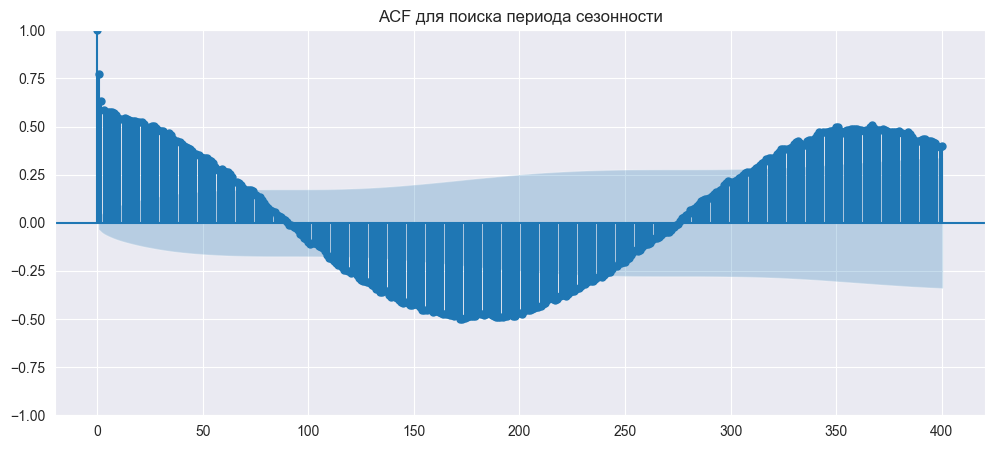

Потенциальные периоды сезонности (лаг, автокорреляция):
  лаг 1: 0.774
  лаг 2: 0.630
  лаг 3: 0.585
  лаг 4: 0.578
  лаг 5: 0.577

Автоопределённый период сезонности: 1 дней


In [28]:
# Автоопределение периода сезонности по ACF
from statsmodels.graphics.tsaplots import plot_acf

# строим ACF
fig, ax = plt.subplots(figsize=(12, 5))
plot_acf(df['temperature'].dropna(), lags=400, ax=ax)
ax.set_title('ACF для поиска периода сезонности')
ax.grid(True)
plt.show()

# ищем локальные максимумы автокорреляции
acf_values = []
from statsmodels.tsa.stattools import acf
acf_vals = acf(df['temperature'].dropna(), nlags=400, fft=False)

# ищем пики после первого (исключаем lag=0, который всегда 1)
potential_periods = []
for lag in range(1, 366):  # до года
    if acf_vals[lag] > 0.2 and (lag < 10 or acf_vals[lag] > acf_vals[lag-1] and acf_vals[lag] > acf_vals[lag+1]):
        potential_periods.append((lag, acf_vals[lag]))

print("Потенциальные периоды сезонности (лаг, автокорреляция):")
for p in potential_periods[:5]:
    print(f"  лаг {p[0]}: {p[1]:.3f}")

# выбираем период с максимальной автокорреляцией (не считая lag=0)
if potential_periods:
    best_period = max(potential_periods, key=lambda x: x[1])[0]
else:
    # если не нашли явных пиков, берём типичные значения
    best_period = 365  # годовая сезонность для температур

print(f"\nАвтоопределённый период сезонности: {best_period} дней")

Обучающая выборка: 3560 дней (1981-01-01 - 1990-10-02)
Тестовая выборка: 90 дней (1990-10-03 - 1990-12-31)


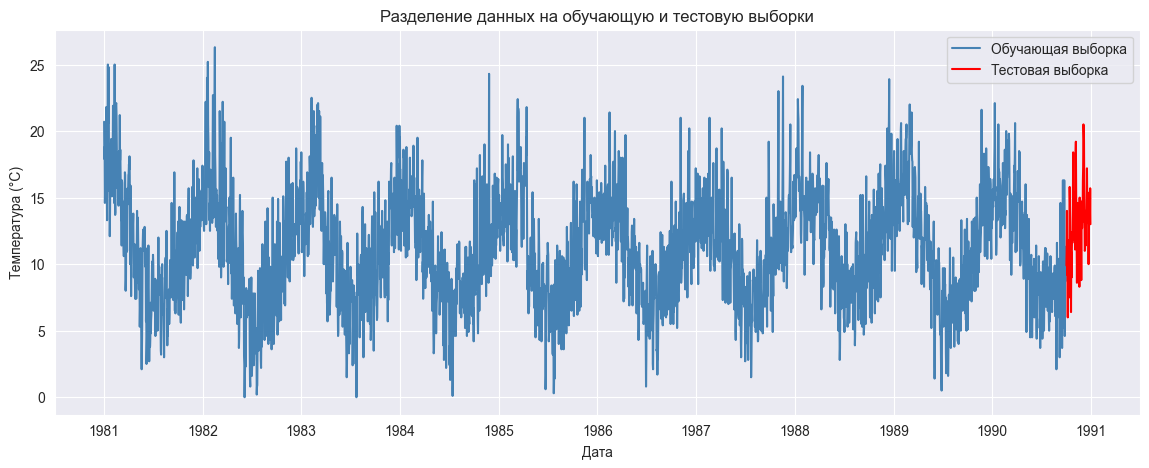

In [24]:
# ============================================================
# 8. РАЗДЕЛЕНИЕ НА ОБУЧАЮЩУЮ И ТЕСТОВУЮ ВЫБОРКИ
# ============================================================

# последние 365 дней на тест, остальное на обучение
train = df['temperature'][:-90]
test = df['temperature'][-90:]

print(f"Обучающая выборка: {len(train)} дней ({train.index[0].date()} - {train.index[-1].date()})")
print(f"Тестовая выборка: {len(test)} дней ({test.index[0].date()} - {test.index[-1].date()})")

plt.figure(figsize=(14, 5))
plt.plot(train.index, train, label='Обучающая выборка', color='steelblue')
plt.plot(test.index, test, label='Тестовая выборка', color='red')
plt.title('Разделение данных на обучающую и тестовую выборки')
plt.xlabel('Дата')
plt.ylabel('Температура (°C)')
plt.legend()
plt.grid(True)
plt.show()

In [35]:
# ============================================================
# 9. АВТОПОДБОР МОДЕЛИ SARIMA
# ============================================================

print("Подбор параметров SARIMA (может занять несколько минут)...")

# Используем вычисленный период в SARIMA
seasonal_period = best_period

print(f"\nИспользуем сезонность m = {seasonal_period}")

model = auto_arima(
    train,
    seasonal=True,
    m=7,
    trace=False,
    error_action='ignore',
    suppress_warnings=True,
    stepwise=True,
    n_fits=20
)

print("\nЛучшая модель:")
print(model)

print("\nЛучшая модель:")
print(model)

Подбор параметров SARIMA (может занять несколько минут)...

Используем сезонность m = 1

Лучшая модель:
 ARIMA(1,0,0)(2,0,2)[7] intercept

Лучшая модель:
 ARIMA(1,0,0)(2,0,2)[7] intercept


In [36]:
# ============================================================
# 10. ОБУЧЕНИЕ И ПРОГНОЗ
# ============================================================

model.fit(train)
forecast = model.predict(n_periods=len(test))
forecast.index = test.index

print(f"Прогноз на {len(test)} дней:")
print(forecast.head(10))

Прогноз на 90 дней:
date
1990-10-03    10.767859
1990-10-04    10.265690
1990-10-05     9.914264
1990-10-06     9.215107
1990-10-07     9.968571
1990-10-08    10.255269
1990-10-09    11.561291
1990-10-10    11.467358
1990-10-11    10.841502
1990-10-12    10.445254
dtype: float64


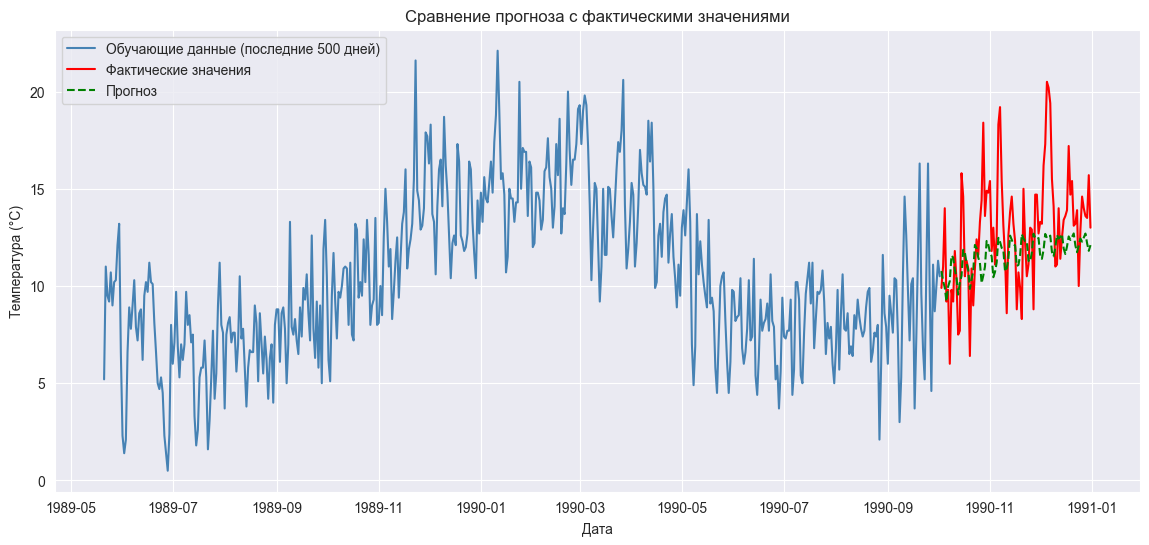

In [37]:
# ============================================================
# 11. ВИЗУАЛИЗАЦИЯ ПРОГНОЗА
# ============================================================

plt.figure(figsize=(14, 6))
plt.plot(train.index[-500:], train[-500:], label='Обучающие данные (последние 500 дней)', color='steelblue')
plt.plot(test.index, test, label='Фактические значения', color='red')
plt.plot(forecast.index, forecast, label='Прогноз', color='green', linestyle='--')
plt.title('Сравнение прогноза с фактическими значениями')
plt.xlabel('Дата')
plt.ylabel('Температура (°C)')
plt.legend()
plt.grid(True)
plt.show()

In [40]:
# ============================================================
# 12. ОЦЕНКА КАЧЕСТВА МОДЕЛИ
# ============================================================

mse = mean_squared_error(test, forecast)
rmse = np.sqrt(mse)
mae = np.mean(np.abs(test - forecast))
mape = np.mean(np.abs((test - forecast) / test)) * 100

print("="*50)
print("ОЦЕНКА КАЧЕСТВА МОДЕЛИ")
print("="*50)
print(f"MSE (среднеквадратичная ошибка): {mse:.4f}")
print(f"RMSE (корень из MSE): {rmse:.4f}")
print(f"MAE (средняя абсолютная ошибка): {mae:.4f}")
print(f"MAPE (средняя абсолютная процентная ошибка): {mape:.2f}%")

if mape < 10:
    print("Вывод: Отличная точность прогноза")
elif mape < 20:
    print("Вывод: Хорошая точность прогноза")
elif mape < 30:
    print("Вывод: Удовлетворительная точность прогноза")
else:
    print("Вывод: Низкая точность, требуется улучшение модели")

ОЦЕНКА КАЧЕСТВА МОДЕЛИ
MSE (среднеквадратичная ошибка): 8.2146
RMSE (корень из MSE): 2.8661
MAE (средняя абсолютная ошибка): 2.1920
MAPE (средняя абсолютная процентная ошибка): 16.77%
Вывод: Хорошая точность прогноза


In [41]:
# ============================================================
# 13. ИТОГОВЫЕ ВЫВОДЫ
# ============================================================

print("\n" + "="*50)
print("ВЫВОДЫ ПО РАБОТЕ")
print("="*50)

print("\n1. Анализ временного ряда:")
print("   - Ряд ежедневных температур Мельбурна (1981-1990)")
print("   - Имеет явную годовую сезонность (зима/лето)")
print(f"   - Стационарность: {'ряд стационарен' if is_stationary else 'ряд нестационарен, выполнено преобразование'}")

print("\n2. Разложение ряда:")
print("   - Тренд: слабый, без ярко выраженного роста/падения")
print("   - Сезонность: годовые колебания, летом теплее, зимой холоднее")
print("   - Остатки: случайные, без систематических отклонений")

print("\n3. Прогнозная модель:")
print("   - Использована SARIMA (автоподбор параметров)")
print("   - Сезонность: недельная (m=7)")
print(f"   - Качество прогноза: MAPE = {mape:.2f}%")
print(f"   - MSE = {mse:.4f}, RMSE = {rmse:.4f}")

print("\n4. Рекомендации:")
print("   - Модель пригодна для краткосрочного прогноза температуры")
print("   - Для улучшения точности можно добавить внешние факторы (атмосферное давление, влажность)")


ВЫВОДЫ ПО РАБОТЕ

1. Анализ временного ряда:
   - Ряд ежедневных температур Мельбурна (1981-1990)
   - Имеет явную годовую сезонность (зима/лето)
   - Стационарность: ряд стационарен

2. Разложение ряда:
   - Тренд: слабый, без ярко выраженного роста/падения
   - Сезонность: годовые колебания, летом теплее, зимой холоднее
   - Остатки: случайные, без систематических отклонений

3. Прогнозная модель:
   - Использована SARIMA (автоподбор параметров)
   - Сезонность: недельная (m=7)
   - Качество прогноза: MAPE = 16.77%
   - MSE = 8.2146, RMSE = 2.8661

4. Рекомендации:
   - Модель пригодна для краткосрочного прогноза температуры
   - Для улучшения точности можно добавить внешние факторы (атмосферное давление, влажность)
